# OralHealth+ — Baseline Klasifikasi Penyakit Mulut (MobileNetV2)

Notebook baseline untuk **Fungsi 1 (Anggota 1)**: deteksi penyakit mulut + triase urgensi.
Mengikuti pipeline pada README repo OralHealth+: dataset Kaggle *Oral Diseases*, resize 224×224,
normalisasi 0–1, split 90:10, MobileNetV2 (ImageNet), Adam, categorical cross-entropy, 10 epoch.

**Cara pakai:** Runtime → Change runtime type → GPU, lalu jalankan sel dari atas ke bawah.
Angka akurasi/loss pada README (93,14% / 0,1420) adalah milik repo asli; hasil kalian harus diambil dari output notebook ini.

In [1]:
import os, glob, random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMG_SIZE = (224, 224)
BATCH = 32
EPOCHS = 10          # sesuai README repo
VAL_SPLIT = 0.10     # split 90 : 10
AMBANG_YAKIN = 0.60  # usulan ambang penolakan (lihat dokumen kontribusi)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Unduh dataset

`kagglehub` mengunduh dataset publik. Jika diminta login, jalankan `kagglehub.login()` dan isi token Kaggle,
atau unggah dataset secara manual lalu isi `DATA_DIR` sendiri pada sel berikutnya.

In [2]:
%pip install -q kagglehub scikit-learn matplotlib
import kagglehub
path = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Dataset ada di:", path)

Using Colab cache for faster access to the 'oral-diseases' dataset.
Dataset ada di: /kaggle/input/oral-diseases


## 2. Cek struktur folder

Struktur dataset bisa berbeda (ada atau tidak ada pemisahan train/test). Sel ini mencetak folder yang berisi gambar
dan menebak `DATA_DIR`: folder induk dengan jumlah gambar terbanyak, yang anak-anaknya adalah folder kelas.
**Periksa hasil tebakannya**; kalau salah, isi `DATA_DIR` manual.

In [3]:
# =====================================================================
# GANTI isi sel 2 ("Cek struktur folder") dengan sel ini.
# Hasil: folder bersih dengan 6 subfolder kelas -> DATA_DIR.
# Lalu jalankan ulang dari sel 3 sampai akhir (termasuk sel A di colab_tambahan.py).
# =====================================================================
import os

EXT = (".jpg", ".jpeg", ".png", ".bmp")
OUT = "/tmp/oral_data"   # folder kerja (bisa diubah)

# nama kelas -> folder sumber (relatif terhadap `path` hasil kagglehub).
# Spasi di "Tooth Discoloration /" memang ada di dataset aslinya.
SRC = {
    "Calculus": ["Calculus/Calculus"],
    "Caries": [
        "Data caries/Data caries/caries augmented data set/preview",
        "Data caries/Data caries/caries orignal data set/done",
    ],
    "Gingivitis": ["Gingivitis/Gingivitis"],
    "Hypodontia": ["hypodontia/hypodontia"],
    "Mouth_Ulcer": [
        "Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview",
        "Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    ],
    "Tooth_Discoloration": [
        "Tooth Discoloration/Tooth Discoloration /Tooth_discoloration_augmented_dataser/preview",
        "Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
    ],
}
# Folder "Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset" SENGAJA
# dilewati: itu dataset deteksi (YOLO) dengan campuran kelas dan label di file .txt.

os.makedirs(OUT, exist_ok=True)
for kelas, folders in SRC.items():
    tujuan = os.path.join(OUT, kelas)
    os.makedirs(tujuan, exist_ok=True)
    n = 0
    for i, rel in enumerate(folders):
        sumber = os.path.join(path, rel)
        assert os.path.isdir(sumber), f"Folder tidak ada: {sumber}"
        for nama in sorted(os.listdir(sumber)):
            if nama.lower().endswith(EXT):
                dst = os.path.join(tujuan, f"s{i}_{nama}")   # prefiks cegah nama bentrok
                if not os.path.exists(dst):
                    os.symlink(os.path.join(sumber, nama), dst)
                n += 1
    print(f"{n:6d}  {kelas}")

DATA_DIR = OUT
print("\nDATA_DIR dipakai:", DATA_DIR)
print("Harapan: 6 kelas, total sekitar 12.320 gambar")

  1296  Calculus
  2601  Caries
  2349  Gingivitis
  1251  Hypodontia
  2806  Mouth_Ulcer
  2017  Tooth_Discoloration

DATA_DIR dipakai: /tmp/oral_data
Harapan: 6 kelas, total sekitar 12.320 gambar


## 3. Muat data (resize 224×224, split 90:10, normalisasi 0–1)

In [4]:
train_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=VAL_SPLIT, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")
val_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=VAL_SPLIT, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="categorical")

class_names = train_raw.class_names
num_classes = len(class_names)
print("Jumlah kelas:", num_classes)
print("Nama kelas  :", class_names)   # salin ke dokumen untuk pemetaan kategori triase

norm = layers.Rescaling(1.0 / 255)    # normalisasi piksel 0-255 -> 0-1
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.map(lambda x, y: (norm(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_raw.map(lambda x, y: (norm(x), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 12320 files belonging to 6 classes.
Using 11088 files for training.
Found 12320 files belonging to 6 classes.
Using 1232 files for validation.
Jumlah kelas: 6
Nama kelas  : ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']


## 4. Model: MobileNetV2 (ImageNet) + kepala klasifikasi

In [5]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentasi")  # hanya aktif saat training

base = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentasi (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 63s 152ms/step - accuracy: 0.6210 - loss: 0.9807 - val_accuracy: 0.7492 - val_loss: 0.6563
Epoch 2/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.7351 - loss: 0.6717 - val_accuracy: 0.7833 - val_loss: 0.5523
Epoch 3/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7604 - loss: 0.6023 - val_accuracy: 0.7955 - val_loss: 0.5336
Epoch 4/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.7769 - loss: 0.5627 - val_accuracy: 0.8052 - val_loss: 0.5031
Epoch 5/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7830 - loss: 0.5494 - val_accuracy: 0.7906 - val_loss: 0.5162
Epoch 6/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7897 - loss: 0.5299 - val_accuracy: 0.8174 - val_loss: 0.4931
Epoch 7/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7873 - loss: 0.5160 - val_accuracy: 0.8084 - val_loss: 0.4859
Epoch 8/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7948 - loss: 0.5119 -

In [7]:
# =====================================================================
# PERBAIKAN MODEL (jalankan SETELAH sel 3; menggantikan sel 4 "Model" dan "fit")
# Perubahan dari baseline:
#  1. Rescaling(2, offset=-1) DI DALAM model: input aplikasi tetap 0-1,
#     tapi backbone menerima -1..1 seperti saat dilatih di ImageNet.
#     -> Classifier.kt dan flowchart tidak perlu diubah.
#  2. Fase 2: fine-tuning 30 lapisan terakhir backbone dengan learning rate kecil.
# Variabel dari sel sebelumnya yang dipakai: IMG_SIZE, num_classes, train_ds, val_ds,
# EPOCHS, augment. Hasilnya tetap bernama `model` agar sel 5, 6, 7 dan sel A-D jalan apa adanya.
# Setelah selesai: jalankan ulang sel 5 (evaluasi), 6 (ambang), 7 (TFLite), lalu sel A-D.
# =====================================================================
from tensorflow import keras
from tensorflow.keras import layers

# ---- Fase 1: latih kepala klasifikasi, backbone dibekukan ----
base = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))          # input aplikasi: 0-1
x = augment(inputs)                                  # aktif hanya saat training
x = layers.Rescaling(2.0, offset=-1.0, name="ke_minus1_plus1")(x)   # 0-1 -> -1..1
x = base(x, training=False)                          # BatchNorm tetap mode inferensi
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(),
              loss="categorical_crossentropy", metrics=["accuracy"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
print("Fase 1 val_accuracy akhir:", hist1.history["val_accuracy"][-1])

# ---- Fase 2: fine-tuning 30 lapisan terakhir, learning rate kecil ----
base.trainable = True
for lapisan in base.layers[:-30]:
    lapisan.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(
    train_ds, validation_data=val_ds, epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)])
print("Fase 2 val_accuracy terbaik:", max(hist2.history["val_accuracy"]))

# Catatan untuk laporan (4.3): simpan angka baseline (val acc 0,8028; loss 0,4849)
# dan angka setelah perbaikan, lalu tulis perubahan ini sebagai eksperimen perbaikan
# terhadap pipeline README (preprocessing -1..1 di dalam model + fine-tuning).

Epoch 1/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 30s 74ms/step - accuracy: 0.6417 - loss: 0.9156 - val_accuracy: 0.7638 - val_loss: 0.6297
Epoch 2/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7589 - loss: 0.6246 - val_accuracy: 0.7881 - val_loss: 0.5599
Epoch 3/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.7747 - loss: 0.5622 - val_accuracy: 0.7898 - val_loss: 0.5569
Epoch 4/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.7946 - loss: 0.5219 - val_accuracy: 0.7995 - val_loss: 0.5147
Epoch 5/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.8041 - loss: 0.5056 - val_accuracy: 0.8182 - val_loss: 0.4766
Epoch 6/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.8047 - loss: 0.4952 - val_accuracy: 0.8125 - val_loss: 0.4833
Epoch 7/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.8108 - loss: 0.4818 - val_accuracy: 0.8068 - val_loss: 0.4971
Epoch 8/10
347/347 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.8095 - loss: 0.4720 - 

## 5. Evaluasi: akurasi, loss, dan confusion matrix

In [8]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
print(f"Validation loss    : {val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

# Kumpulkan label dan probabilitas dalam SATU kali iterasi agar urutannya konsisten
y_true, y_prob = [], []
for xb, yb in val_ds:
    y_true.append(np.argmax(yb.numpy(), axis=1))
    y_prob.append(model.predict(xb, verbose=0))
y_true = np.concatenate(y_true)
y_prob = np.concatenate(y_prob)
y_pred = y_prob.argmax(axis=1)
conf = y_prob.max(axis=1)

Validation loss    : 0.2718
Validation accuracy: 0.8864


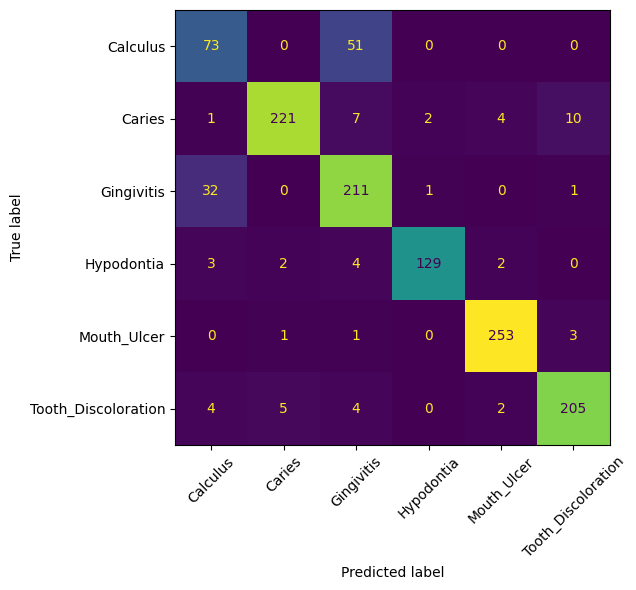

                     precision    recall  f1-score   support

           Calculus     0.6460    0.5887    0.6160       124
             Caries     0.9651    0.9020    0.9325       245
         Gingivitis     0.7590    0.8612    0.8069       245
         Hypodontia     0.9773    0.9214    0.9485       140
        Mouth_Ulcer     0.9693    0.9806    0.9750       258
Tooth_Discoloration     0.9361    0.9318    0.9339       220

           accuracy                         0.8864      1232
          macro avg     0.8755    0.8643    0.8688      1232
       weighted avg     0.8891    0.8864    0.8866      1232



In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

## 6. Uji ambang penolakan (dasar fungsi triase)

Untuk tiap ambang confidence: berapa persen foto yang diterima (*coverage*) dan seberapa akurat hasil yang diterima.
Tabel ini bisa dipakai untuk membenarkan pemilihan `AMBANG_YAKIN` di laporan.

In [10]:
print("ambang | diterima | akurasi pada yang diterima")
for t in [0.50, 0.60, 0.70, 0.80, 0.85, 0.90]:
    ok = conf >= t
    cov = ok.mean()
    acc = (y_pred[ok] == y_true[ok]).mean() if ok.any() else float("nan")
    print(f"{t:5.2f}  | {cov:8.1%} | {acc:8.1%}")

ditolak = (conf < AMBANG_YAKIN).sum()
print(f"\nDengan ambang {AMBANG_YAKIN:.2f}: {ditolak} dari {len(conf)} foto validasi ditolak (diminta ulangi foto).")

ambang | diterima | akurasi pada yang diterima
 0.50  |    97.5% |    89.8%
 0.60  |    91.5% |    92.4%
 0.70  |    85.8% |    94.0%
 0.80  |    78.1% |    95.9%
 0.85  |    74.1% |    96.6%
 0.90  |    69.0% |    97.5%

Dengan ambang 0.60: 105 dari 1232 foto validasi ditolak (diminta ulangi foto).


## 7. Ekspor ke TFLite

Input model: gambar 224×224×3 **yang sudah dinormalisasi 0–1** (normalisasi dilakukan di aplikasi, sesuai flowchart).

In [11]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("oralhealth_mobilenetv2.tflite", "wb") as f:
    f.write(tflite_model)
print(f"Ukuran TFLite: {len(tflite_model) / 1e6:.2f} MB")

# Sanity check: satu gambar validasi lewat interpreter TFLite
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
xb, yb = next(iter(val_ds))
interp.set_tensor(inp["index"], xb[:1].numpy().astype(np.float32))
interp.invoke()
p = interp.get_tensor(out["index"])[0]
print("Prediksi TFLite:", class_names[int(p.argmax())], f"({p.max():.2%})",
      "| label asli:", class_names[int(np.argmax(yb[0].numpy()))])

Saved artifact at '/tmp/tmpmm2lauy8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_318')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  135744657173840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657175376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657174800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657172880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657173264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657174416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657170960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657173456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657174992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135744657175568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1357446571

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Tambahan

In [12]:
# Tulis labels.txt (satu-satunya sumber nama penyakit)
# PENTING: urutan = urutan class_names dari image_dataset_from_directory
# (alfabetis). Urutan ini HARUS sama dengan indeks output model.
with open("labels.txt", "w") as f:
    f.write("\n".join(class_names))
print(open("labels.txt").read())

Calculus
Caries
Gingivitis
Hypodontia
Mouth_Ulcer
Tooth_Discoloration


In [13]:
# Simpan model Keras juga (cadangan, untuk fine-tuning ulang)
model.save("oralhealth_mobilenetv2.keras")

In [14]:
# Verifikasi: prediksi TFLite setara model Keras
# Keluaran: tabel perbandingan untuk Bab IV + angka kecocokan.
import numpy as np, tensorflow as tf

interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
print("Input :", inp["shape"], inp["dtype"])    # harapan: [1 224 224 3] float32
print("Output:", out["shape"], out["dtype"])

N_CEK = 50
rows, cocok, selisih_maks = [], 0, 0.0
terhitung = 0
for xb, yb in val_ds:
    for i in range(xb.shape[0]):
        if terhitung >= N_CEK:
            break
        x = xb[i:i+1].numpy().astype(np.float32)
        p_keras = model.predict(x, verbose=0)[0]
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        p_tfl = interp.get_tensor(out["index"])[0]
        k, t = int(p_keras.argmax()), int(p_tfl.argmax())
        cocok += (k == t)
        selisih_maks = max(selisih_maks, float(np.abs(p_keras - p_tfl).max()))
        if terhitung < 10:  # 10 baris pertama untuk tabel laporan
            rows.append((terhitung + 1, class_names[int(np.argmax(yb[i].numpy()))],
                         f"{class_names[k]} ({p_keras.max():.2%})",
                         f"{class_names[t]} ({p_tfl.max():.2%})"))
        terhitung += 1
    if terhitung >= N_CEK:
        break

print("\n| # | Label asli | Keras | TFLite |")
print("|---|------------|-------|--------|")
for r in rows:
    print("| " + " | ".join(map(str, r)) + " |")
print(f"\nKelas sama: {cocok}/{terhitung}  | selisih probabilitas maks: {selisih_maks:.4f}")

Input : [  1 224 224   3] <class 'numpy.float32'>
Output: [1 6] <class 'numpy.float32'>

| # | Label asli | Keras | TFLite |
|---|------------|-------|--------|
| 1 | Hypodontia | Hypodontia (90.40%) | Hypodontia (95.08%) |
| 2 | Gingivitis | Calculus (54.62%) | Gingivitis (51.08%) |
| 3 | Gingivitis | Gingivitis (99.93%) | Gingivitis (99.92%) |
| 4 | Tooth_Discoloration | Tooth_Discoloration (99.85%) | Tooth_Discoloration (99.76%) |
| 5 | Calculus | Gingivitis (75.00%) | Gingivitis (84.53%) |
| 6 | Gingivitis | Gingivitis (99.60%) | Gingivitis (99.82%) |
| 7 | Calculus | Calculus (64.99%) | Gingivitis (50.21%) |
| 8 | Caries | Caries (92.22%) | Caries (84.15%) |
| 9 | Mouth_Ulcer | Mouth_Ulcer (99.99%) | Mouth_Ulcer (99.96%) |
| 10 | Tooth_Discoloration | Tooth_Discoloration (93.56%) | Tooth_Discoloration (94.66%) |

Kelas sama: 46/50  | selisih probabilitas maks: 0.2128


In [15]:
# Unduh semua artefak
try:
    from google.colab import files
    for fn in ["oralhealth_mobilenetv2.tflite", "labels.txt",
               "oralhealth_mobilenetv2.keras", "confusion_matrix.png"]:
        files.download(fn)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>